In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

In [2]:
MONO_BLACK = "0.00"
MONO_DARK = "0.30"
MONO_MID = "0.55"
MONO_LIGHT = "0.82"

# 第9章 トレンドと状態を読む


## 第9章 第4節 第1項のコード

### 日ごとの売上データの生成とProphetの入力形式への変換

第4節「実践：Pythonによる時系列予測と構造時系列モデルの構築」の第1項「Prophetによる365日先までの自動需要予測」のコードです。

Prophetへの入力は `ds`（日付型）と `y`（数値型）の2列に統一されています。Polarsでデータを準備し、Prophetが要求するpandas形式に変換します。まず、トレンド・年次季節性・週次季節性・ノイズを持つ日ごとの売上データを生成します。

#### 処理内容

1. **ライブラリのインポート**
   `polars`、`numpy`、`prophet`、`matplotlib`をインポートし、日本語フォントを設定する。

2. **日ごとの売上データの生成**
   `np.random.seed(42)`で再現性を確保し、3年分（2022〜2024年）の日ごとの売上データを生成する。トレンド・年次季節性・週次季節性・ノイズを合成する。

3. **データの確認**
   `df.head()`で先頭の5行を表示して内容を確認する。


In [3]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from prophet import Prophet

# 日ごとの売上データの生成（実務では CSV や DB から読み込む）
np.random.seed(42)
dates = pl.date_range(
    start=pl.date(2022, 1, 1),
    end=pl.date(2024, 12, 31),
    interval="1d",
    eager=True,
)

# トレンド + 年次季節性 + 週次季節性 + ノイズ
t = np.arange(len(dates))
trend = 1_000_000 + t * 500
yearly = 300_000 * np.sin(2 * np.pi * t / 365.25 - np.pi / 2)
weekly = 100_000 * np.sin(2 * np.pi * t / 7)
noise = np.random.normal(0, 80_000, len(dates))

sales = (trend + yearly + weekly + noise).clip(min=0)

df = pl.DataFrame({"date": dates, "sales": sales.astype(int)})
df.head()

Importing plotly failed. Interactive plots will not work.


date,sales
date,i64
2022-01-01,739737
2022-01-02,767666
2022-01-03,850485
2022-01-04,867130
2022-01-05,640589


### Prophetの入力形式への変換

Polars DataFrameをProphetが要求するpandas形式（`ds`, `y`列）に変換し、型と行列サイズを確認する。


In [4]:
# Prophet の入力形式（ds, y）に変換
# Polars → pandas は .to_pandas() で変換
prophet_df = df.rename({"date": "ds", "sales": "y"}).to_pandas()
prophet_df["ds"] = pd.to_datetime(prophet_df["ds"]).astype("datetime64[ns]")

# 変数の型と行列サイズを確認
print(f"変数の型:\n{prophet_df.dtypes}")
print(f"行列サイズ: {prophet_df.shape}")

変数の型:
ds    datetime64[ns]
y              int64
dtype: object
行列サイズ: (1096, 2)


### モデルの構築：祝日の設定と変化点の調整

Prophetのモデルを定義し、日本の祝日カレンダーと予測区間の幅を設定して学習する。2024年10月から12月までの92日間は検証用に取り分ける。

#### 処理内容

1. **Prophetで使うモデルの定義**
   年次・週次季節性を有効化し、変化点の柔軟さ（`changepoint_prior_scale=0.05`）と80%予測区間（`interval_width=0.80`）を設定する。

2. **祝日カレンダーの設定**
   `m.add_country_holidays(country_name="JP")` で日本の祝日を自動設定する。

3. **学習**
   2024年10月から12月までの92日間を検証用に取り分ける。検証用モデルはそれ以前のデータ、最終予測用モデルは全データで学習する。


In [5]:
# 同じ設定のProphetモデルを作る関数
def create_prophet_model():
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,  # 日内の変化を扱わない
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10.0,
        interval_width=0.80,
        holidays_prior_scale=10.0,
    )
    model.add_country_holidays(country_name="JP")
    return model


# 2024年10月から12月までの92日間を検証用に取り分ける
train_df = prophet_df[prophet_df["ds"] < "2024-10-01"]
test_df = prophet_df[prophet_df["ds"] >= "2024-10-01"]

# 検証用モデルと、全データで学習する最終予測用モデル
m_eval = create_prophet_model().fit(train_df)
m = create_prophet_model().fit(prophet_df)
print("検証用の学習件数:", len(train_df))
print("最終予測用の学習件数:", len(prophet_df))

17:50:41 - cmdstanpy - INFO - Chain [1] start processing


17:50:41 - cmdstanpy - INFO - Chain [1] done processing


17:50:41 - cmdstanpy - INFO - Chain [1] start processing


17:50:41 - cmdstanpy - INFO - Chain [1] done processing


検証用の学習件数: 1004
最終予測用の学習件数: 1096


### 365日先の予測

学習済みモデルを使って365日先までの予測値と予測区間を計算し、主要カラムを確認する。


In [6]:
# 全データの最終日から未来365日の予測用DataFrameを作成
future = m.make_future_dataframe(periods=365, freq="D")

# 予測実行
np.random.seed(42)
forecast = m.predict(future)

# 主要カラムを確認
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10))

             ds          yhat    yhat_lower    yhat_upper
1451 2025-12-22  1.542800e+06  1.441170e+06  1.635896e+06
1452 2025-12-23  1.508077e+06  1.412290e+06  1.597993e+06
1453 2025-12-24  1.407753e+06  1.304005e+06  1.506820e+06
1454 2025-12-25  1.364312e+06  1.263253e+06  1.464461e+06
1455 2025-12-26  1.393761e+06  1.295529e+06  1.490894e+06
1456 2025-12-27  1.470222e+06  1.374200e+06  1.566811e+06
1457 2025-12-28  1.547208e+06  1.445335e+06  1.644410e+06
1458 2025-12-29  1.549448e+06  1.453389e+06  1.647944e+06
1459 2025-12-30  1.512872e+06  1.415659e+06  1.610277e+06
1460 2025-12-31  1.410628e+06  1.311649e+06  1.513057e+06


### 予測結果のプロット

予測値と実績値を同じ図に重ね、検証用の期間と将来を予測する期間を図で確認する。実績は実線、Prophetによる予測は破線に統一する。80%予測区間には斜線を加え、グレースケールでも系列を識別できるようにする。


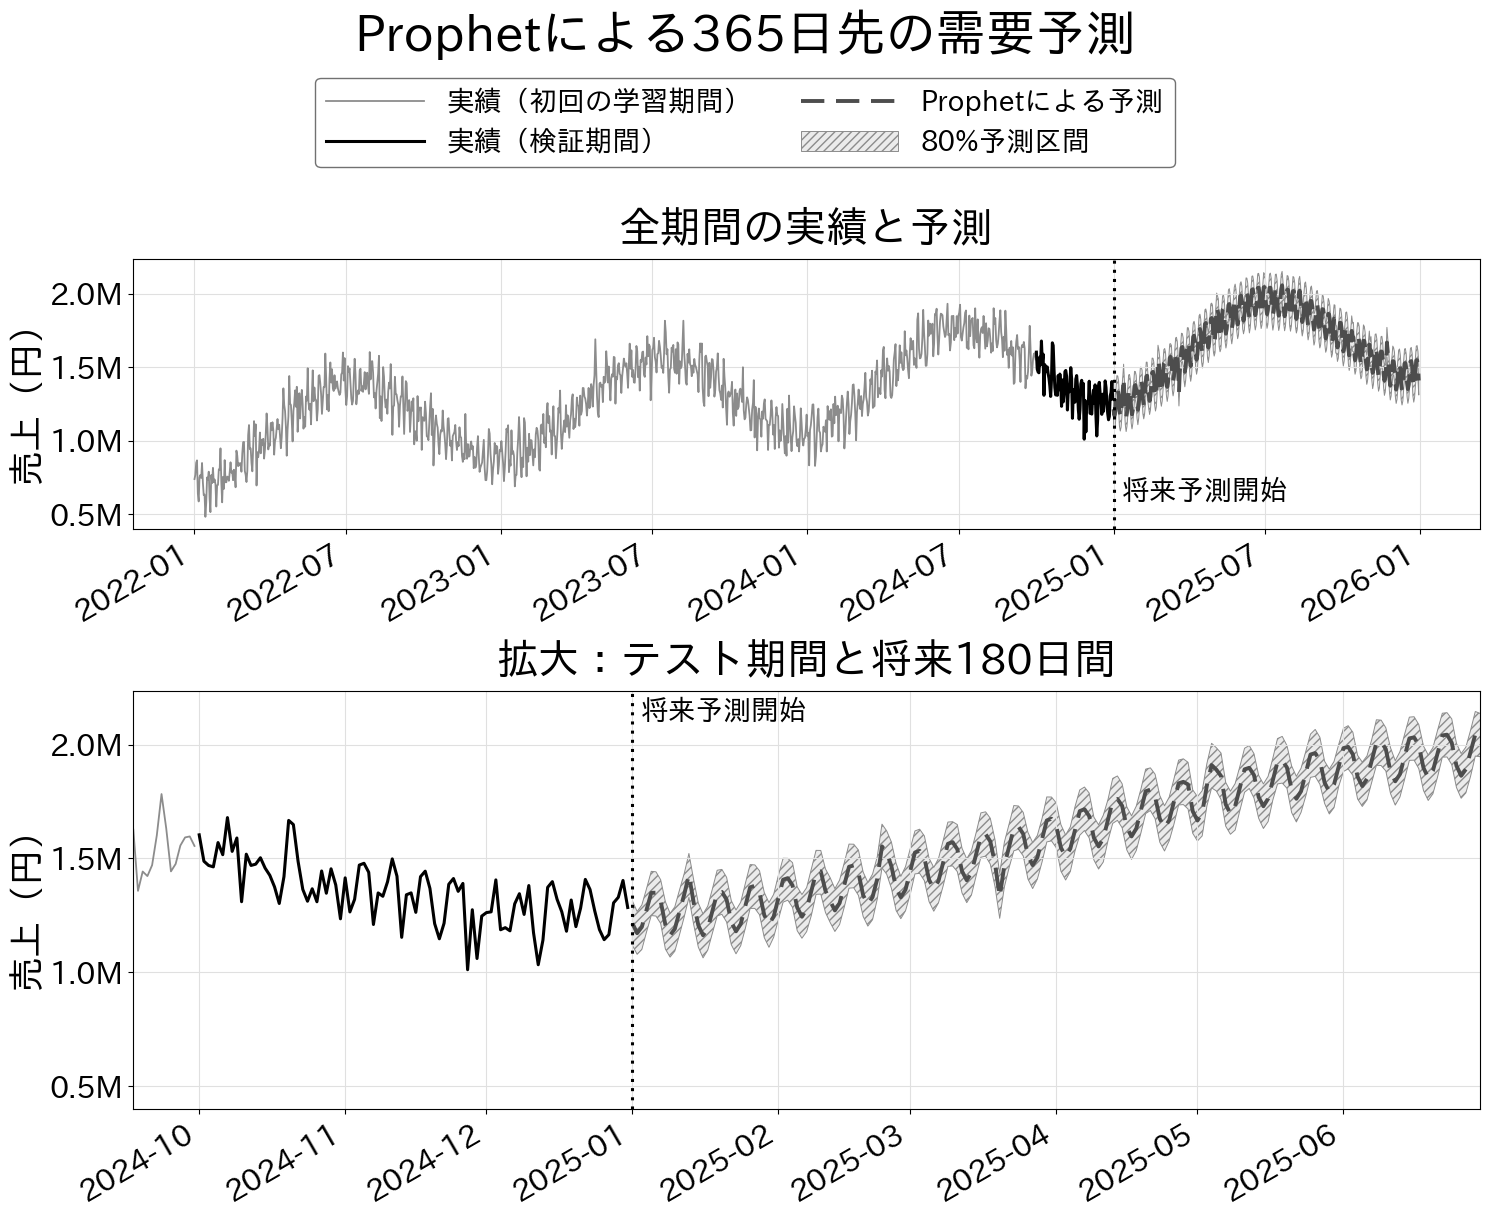

In [7]:
# 上段は全期間の俯瞰図、下段はテスト期間と将来予測の詳細図とする
pred = forecast[forecast["ds"] > prophet_df["ds"].max()].copy()
boundary_date = prophet_df["ds"].max() + pd.Timedelta(days=1)
zoom_start = test_df["ds"].min() - pd.Timedelta(days=14)
zoom_end = min(boundary_date + pd.Timedelta(days=180), pred["ds"].max())

fig, (ax_full, ax_zoom) = plt.subplots(
    2, 1, figsize=(15, 12), height_ratios=[1, 1.55]
)

for ax in (ax_full, ax_zoom):
    # 予測区間を先に描き、実績線と予測線が帯の上ではっきり見えるようにする
    ax.fill_between(
        pred["ds"],
        pred["yhat_lower"],
        pred["yhat_upper"],
        facecolor="0.92",
        edgecolor=MONO_MID,
        hatch="////",
        linewidth=0.7,
        label="80%予測区間",
        zorder=1,
    )
    # 実績は実線、予測は破線に統一し、マーカーは使用しない
    ax.plot(
        train_df["ds"],
        train_df["y"],
        color=MONO_MID,
        lw=1.3,
        label="実績（初回の学習期間）",
        zorder=2,
    )
    ax.plot(
        test_df["ds"],
        test_df["y"],
        color=MONO_BLACK,
        lw=2.2,
        label="実績（検証期間）",
        zorder=4,
    )
    ax.plot(
        pred["ds"],
        pred["yhat"],
        color=MONO_DARK,
        lw=2.8,
        ls=(0, (6, 3)),
        label="Prophetによる予測",
        zorder=3,
    )
    ax.axvline(
        boundary_date, color=MONO_BLACK, lw=2.2, ls=(0, (1, 2)), zorder=5
    )
    annotation_y = 0.06 if ax is ax_full else 1.0
    annotation_offset = (6, 6) if ax is ax_full else (6, -6)
    annotation_va = "bottom" if ax is ax_full else "top"
    ax.annotate(
        "将来予測開始",
        xy=(boundary_date, annotation_y),
        xycoords=("data", "axes fraction"),
        xytext=annotation_offset,
        textcoords="offset points",
        fontsize=20,
        color=MONO_BLACK,
        ha="left",
        va=annotation_va,
    )
    ax.set_ylabel("売上（円）", fontsize=26)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M")
    )
    ax.grid(color="0.88", linewidth=0.8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="both", labelsize=22)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

ax_full.set_title("全期間の実績と予測", fontsize=30, pad=12)
ax_zoom.set_title("拡大：テスト期間と将来180日間", fontsize=30, pad=12)
ax_zoom.set_xlim(zoom_start, zoom_end)

fig.suptitle("Prophetによる365日先の需要予測", fontsize=36, y=1.01)
handles, labels = ax_zoom.get_legend_handles_labels()
legend_order = [1, 2, 3, 0]  # 実績、予測、予測区間の順に並べる
fig.legend(
    [handles[i] for i in legend_order],
    [labels[i] for i in legend_order],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    fontsize=20,
    handlelength=3.5,
    columnspacing=1.8,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

### Prophetによる成分分解のグラフ

Prophetが推定したトレンド・季節性・祝日の効果を成分に分けて図で示す。


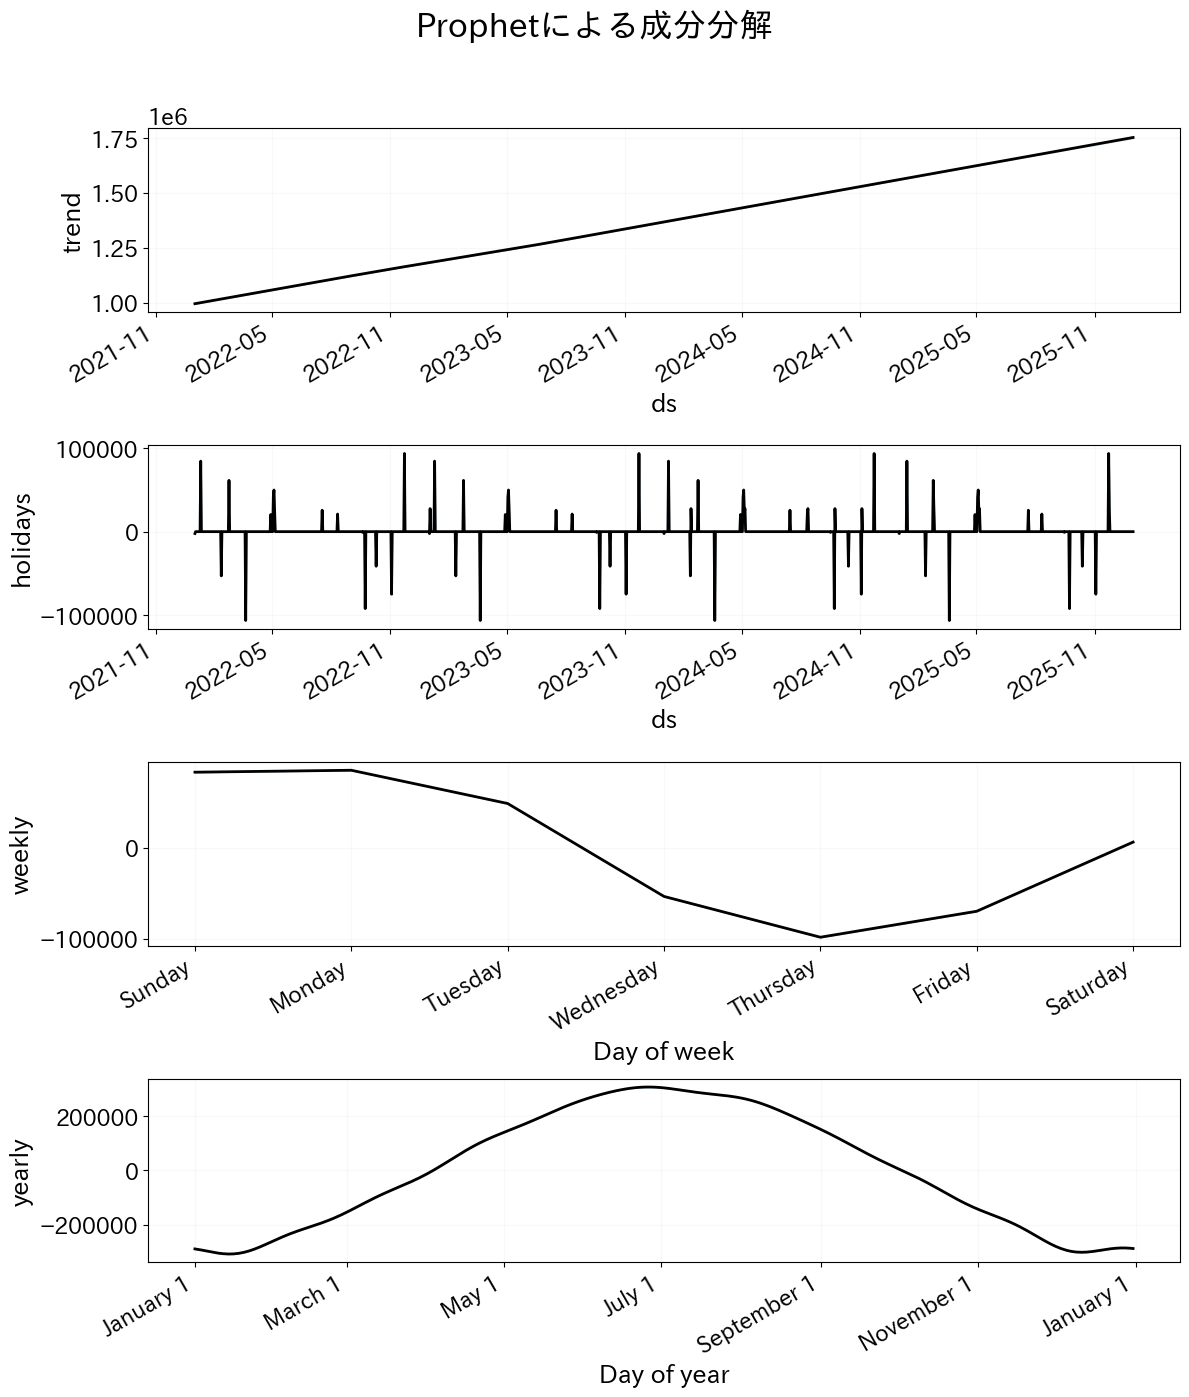

In [8]:
# 成分分解のグラフ（トレンド・週次・年次・祝日の各効果）
plt.rcParams.update(
    {
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 16,
    }
)
fig_comp = m.plot_components(forecast)
fig_comp.set_size_inches(12, 14)
fig_comp.suptitle("Prophetによる成分分解", fontsize=24, y=0.995)

# 全サブプロットのx軸ラベルを個別に回転（autofmt_xdate は中間のラベルを非表示にするため使わない）
for ax in fig_comp.axes:
    for line in ax.get_lines():
        line.set_color(MONO_BLACK)
        line.set_linewidth(2.0)
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(color="0.88", linewidth=0.8)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

fig_comp.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 予測の精度を確認する：テストデータとの比較

取り分けたテスト期間について、MAPE・RMSE・実測値が予測区間内に入った割合を計算する。

#### 処理内容

1. **テスト期間の予測を抽出**
   `forecast` からテスト期間の行を絞り込む。

2. **Polarsで誤差計算**
   テストデータと予測値を結合し、誤差（`error`）と絶対パーセント誤差（`ape`）を計算する。

3. **評価指標の出力**
   MAPE・RMSE・実測値が予測区間内に入った割合（設定値80%）を確認する。


In [ ]:
# 検証用モデルでテスト期間を予測
validation_future = m_eval.make_future_dataframe(periods=len(test_df), freq="D")
np.random.seed(42)
validation_forecast = m_eval.predict(validation_future)

test_forecast = validation_forecast[
    (validation_forecast["ds"] >= test_df["ds"].min())
    & (validation_forecast["ds"] <= test_df["ds"].max())
].copy()

# Polarsで結合・誤差計算
eval_df = (
    pl.from_pandas(test_df[["ds", "y"]])
    .join(
        pl.from_pandas(
            test_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]]
        ),
        on="ds",
        how="left",
    )
    .with_columns(
        [
            (pl.col("y") - pl.col("yhat")).alias("error"),
            ((pl.col("y") - pl.col("yhat")).abs() / pl.col("y") * 100).alias(
                "ape"
            ),
        ]
    )
)

mape = eval_df["ape"].mean()
rmse = (eval_df["error"] ** 2).mean() ** 0.5

print(f"MAPE: {mape:.2f}%")
print(f"RMSE: {rmse:,.0f} 円")
print("80%予測区間内に実績が収まる割合:")
coverage = (
    eval_df.filter(
        (pl.col("y") >= pl.col("yhat_lower"))
        & (pl.col("y") <= pl.col("yhat_upper"))
    ).height
    / eval_df.height
    * 100
)
print(f"  {coverage:.1f}%（設定値 80%）")

MAPE: 4.34%
RMSE: 73,111 円
80%予測区間内に実績が収まる割合:
  82.6%（設定値 80%）


## 第9章 第4節 第2項のコード

### statsmodels のインストール確認

第4節第2項「statsmodelsによる状態空間モデルの定義と推定」のコードです。

利用する statsmodels のバージョンと、状態空間モデル用クラス `UnobservedComponents` のインポートを確認する。


In [10]:
import statsmodels
from statsmodels.tsa.statespace.structural import UnobservedComponents

print("statsmodels version:", statsmodels.__version__)

# 利用可能なモデルの設定を確認
# help(UnobservedComponents.__init__)

statsmodels version: 0.14.6


### 状態空間モデル用サンプルデータの生成と基本機能の確認

状態空間モデルの挙動を理解しやすくするため、ローカル線形トレンドモデルの仮定に合う日ごとの売上データを生成する。売上は「少しずつ変わる水準と傾き＋週次季節性＋観測ノイズ」で構成する。

statsmodelsはpandas Seriesで入力を受け取るため、indexが日付型で、間隔が1日のSeriesに変換する。

#### 処理内容

1. **サンプルデータの生成**
   `rng = np.random.default_rng(13)`で再現性を確保し、2022〜2024年の日ごとの売上データを生成する。

2. **週次パターンの設定**
   曜日ごとの需要差を基準に、週次季節性が少しずつ変わるように設定する。

3. **pandas Series への変換**
   `pd.Series(...).asfreq("D")`でstatsmodelsが要求する1日間隔のSeriesに変換して先頭を確認する。


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# 状態空間モデルが想定する水準、傾き、週次季節性を持つサンプルデータを作成
rng = np.random.default_rng(13)
dates = pl.date_range(
    start=pl.date(2022, 1, 1),
    end=pl.date(2024, 12, 31),
    interval="1d",
    eager=True,
)
t = np.arange(len(dates))

# 水準と傾きが少しずつ変化するローカル線形トレンド
level = np.empty(len(dates))
slope = np.empty(len(dates))
level[0], slope[0] = 1_000_000, 450
for i in range(1, len(dates)):
    slope[i] = slope[i - 1] + rng.normal(0, 15)
    level[i] = level[i - 1] + slope[i - 1] + rng.normal(0, 3_000)

# 時間とともに少しずつ変わる週次季節性
weekly_pattern = np.array(
    [14_000, 19_000, 6_000, -5_000, -9_000, -7_000, -18_000], dtype=float
)
weekly = np.empty(len(dates))
weekly[:7] = weekly_pattern
for i in range(7, len(dates)):
    weekly[i] = -weekly[i - 6 : i].sum() + rng.normal(0, 1_500)

# 観測ノイズ：状態そのものではなく、日々の偶発的なブレ
noise = rng.normal(0, 20_000, len(dates))
sales = (level + weekly + noise).clip(min=0)

df = pl.DataFrame({"date": dates, "sales": sales.astype(int)})

# statsmodels は pandas Series で受け取る（index が日付型、頻度が日次）
ts = pd.Series(
    df["sales"].to_numpy(),
    index=pd.to_datetime(df["date"].to_numpy()),
    name="sales",
).asfreq("D")
print(f"期間: {ts.index[0].date()} 〜 {ts.index[-1].date()}")
ts.head()

期間: 2022-01-01 〜 2024-12-31


2022-01-01    1028040
2022-01-02     974898
2022-01-03    1007377
2022-01-04     995002
2022-01-05     981929
Freq: D, Name: sales, dtype: int64

### ローカル線形トレンドモデルの定義とパラメータの推定

ローカル線形トレンドモデルと週次季節性を指定し、最尤推定（観測データが最も得られやすくなる値を選ぶ方法）でパラメータを推定する。

#### 処理内容

1. **モデルの定義**
   `level="local linear trend"`（水準＋傾き）と `seasonal=7`（週次季節性）を指定し、初期状態を正確に扱う設定を加える。

2. **パラメータの推定**
   `model.fit(method="powell", disp=False)`で、Powell法による数値最適化（計算を繰り返して条件に最も合う値を探す方法）を使って最尤推定を行う。

3. **結果のまとめの確認**
   `result.summary()`で推定したパラメータ（観測ノイズ・水準ノイズ・傾きノイズ・季節性ノイズ）と対数尤度・AIC・BICを確認する。


In [12]:
# 1. モデルの定義
#   level="local linear trend": ローカル線形トレンドモデル（水準＋傾き）
#   seasonal=7: 週次季節性（周期7）
model = UnobservedComponents(
    ts,
    level="local linear trend",
    seasonal=7,
    use_exact_diffuse=True,
)

# 2. パラメータ推定（最尤推定、Powell法による数値最適化）
result = model.fit(method="powell", disp=False)

# 3. 結果のまとめ
print(result.summary())

                           Unobserved Components Results                            
Dep. Variable:                        sales   No. Observations:                 1096
Model:                   local linear trend   Log Likelihood              -12470.078
                   + stochastic seasonal(7)   AIC                          24964.157
Date:                      Tue, 08 Sep 2026   BIC                          25024.150
Time:                              17:50:44   HQIC                         24986.857
Sample:                          01-01-2022                                         
                               - 12-31-2024                                         
Covariance Type:                        opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular  4.069e+08   2.03e+07     20.079      0.000    3

## 第9章 第4節 第3項のコード

### スムージング済み状態の取り出し

第4節第3項「売上データを『トレンド』『季節』『ノイズ』に分解して可視化」のコードです。

学習済みモデルから、全期間のデータを使って平滑化された状態系列を取り出し、利用可能な成分の名前を確認する。


In [13]:
# 前項で当てはめたresultを使用
# 平滑化した状態系列（全データを使った推定結果）を取り出す
smoothed = result.smoother_results

# 利用可能な成分の名前を確認
print("状態変数の一覧:")
print(result.model.state_names)

状態変数の一覧:
['level', 'trend', 'seasonal', 'seasonal.L1', 'seasonal.L2', 'seasonal.L3', 'seasonal.L4', 'seasonal.L5']


### 成分分解データの整理

取り出した状態系列をPolars DataFrameに整理し、後続の図で使う成分分解データを作成する。初期状態を大きな不確実性から推定し始める影響が残りやすいため、冒頭14日をウォームアップ期間として除外する。

#### 処理内容

1. **各成分の抽出**
   `result.level.smoothed`（水準）、`result.trend.smoothed`（傾き）、`result.seasonal.smoothed`（週次季節性）を取り出す。

2. **残差の計算**
   観測値から水準と季節性の和を引いた残差を計算する。

3. **ウォームアップ期間の除外**
   `decomp.slice(14)`で冒頭14日を除外した表示・比較用DataFrameを作成し、先頭を確認する。


In [14]:
# 各成分をPolars DataFrameに整理
level_vals = result.level.smoothed  # 水準（トレンド）
trend_vals = result.trend.smoothed  # 傾き
seasonal_vals = result.seasonal.smoothed  # 週次季節性
irregular = ts.values - (level_vals + seasonal_vals)  # 残差

decomp = pl.DataFrame(
    {
        "date": df["date"],
        "observed": df["sales"].cast(pl.Float64),
        "level": level_vals,
        "trend_slope": trend_vals,
        "seasonal": seasonal_vals,
        "irregular": irregular,
    }
)

# 初期状態の不確実性の影響が大きい冒頭期間を診断と図から除外する
burn_in_days = 14
decomp_diagnostic = decomp.slice(burn_in_days)
decomp_diagnostic.head()

date,observed,level,trend_slope,seasonal,irregular
date,f64,f64,f64,f64,f64
2022-01-15,1.029998e6,1.0093e6,693.601135,14231.414714,6454.54622
2022-01-16,1.031855e6,1.0109e6,693.433598,15169.293607,5821.536761
2022-01-17,1.022816e6,1.0123e6,693.256063,12982.921941,-2432.562632
2022-01-18,1.023004e6,1.0137e6,693.067641,-2077.387073,11351.568922
2022-01-19,1.023896e6,1.0149e6,692.872477,-17045.00104,26040.642133


### 成分分解の4つのグラフ

観測値・水準（トレンド）・傾き・週次季節性・残差を4つのグラフで示す。冒頭のウォームアップ期間を除外し、初期化による一時的に大きな値を取り除く。


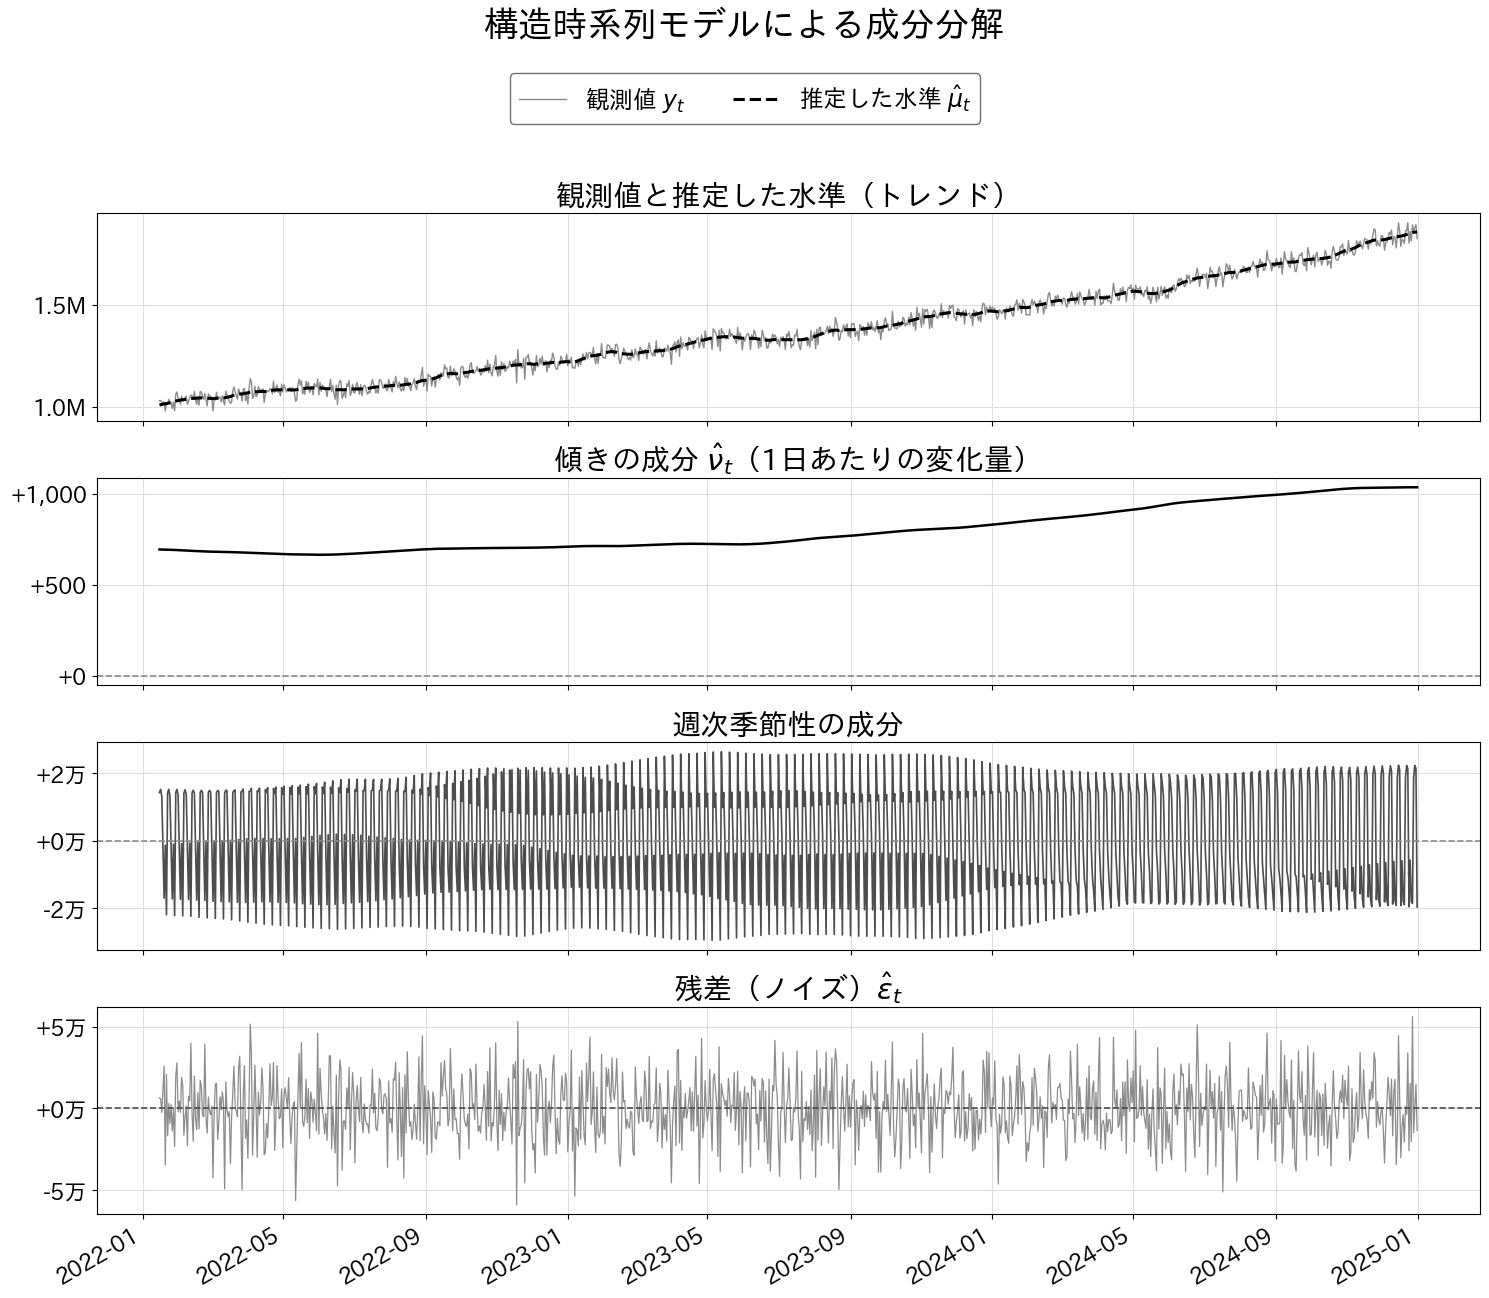

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)

decomp_plot = decomp_diagnostic
date_idx = pd.to_datetime(decomp_plot["date"].to_numpy())

# 1. 観測値と推定した水準（トレンド）
(observed_line,) = axes[0].plot(
    date_idx,
    decomp_plot["observed"],
    color=MONO_MID,
    lw=1.0,
    label="観測値 $y_t$",
)
(level_line,) = axes[0].plot(
    date_idx,
    decomp_plot["level"],
    color=MONO_BLACK,
    lw=2.2,
    ls="--",
    label="推定した水準 $\\hat{\\mu}_t$",
)
axes[0].set_title("観測値と推定した水準（トレンド）", fontsize=21)
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M")
)
axes[0].tick_params(axis="both", labelsize=16)

# 2. 傾きの成分
axes[1].plot(date_idx, decomp_plot["trend_slope"], color=MONO_BLACK, lw=1.8)
axes[1].axhline(0, color=MONO_MID, lw=1.2, ls="--")
axes[1].set_title(
    "傾きの成分 $\\hat{\\nu}_t$（1日あたりの変化量）", fontsize=21
)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+,.0f}"))
axes[1].tick_params(axis="both", labelsize=16)

# 3. 週次季節性
axes[2].plot(date_idx, decomp_plot["seasonal"], color=MONO_DARK, lw=1.2)
axes[2].axhline(0, color=MONO_MID, lw=1.2, ls="--")
axes[2].set_title("週次季節性の成分", fontsize=21)
axes[2].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1e4:+.0f}万")
)
axes[2].tick_params(axis="both", labelsize=16)

# 4. 残差（ノイズ）
axes[3].plot(date_idx, decomp_plot["irregular"], color=MONO_MID, lw=0.9)
axes[3].axhline(0, color=MONO_DARK, lw=1.2, ls="--")
axes[3].set_title("残差（ノイズ）$\\hat{\\varepsilon}_t$", fontsize=21)
axes[3].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1e4:+.0f}万")
)
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[3].tick_params(axis="both", labelsize=16)
fig.autofmt_xdate()

for ax in axes:
    ax.grid(color="0.88", linewidth=0.8)
fig.suptitle("構造時系列モデルによる成分分解", fontsize=25, y=0.995)
fig.legend(
    [observed_line, level_line],
    ["観測値 $y_t$", "推定した水準 $\\hat{\\mu}_t$"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
    fontsize=17,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

### 各成分の変動幅を比較する

各成分の標準偏差を計算し、観測値全体の標準偏差に対する比率（変動幅の目安）を確認する。


In [ ]:
# 各成分の標準偏差と観測値全体に対する標準偏差比を計算
stats_source = decomp_diagnostic
total_var = stats_source["observed"].std()

stats = (
    stats_source.select(
        [
            pl.col("level").std().alias("水準（トレンド）"),
            pl.col("seasonal").std().alias("週次季節性"),
            pl.col("irregular").std().alias("残差（ノイズ）"),
        ]
    )
    .unpivot(variable_name="成分", value_name="標準偏差")
    .with_columns(
        (pl.col("標準偏差") / total_var * 100).alias(
            "標準偏差比（変動幅の目安）"
        )
    )
)
print(f"\n観測値の標準偏差（全体）: {total_var:,.0f} 円")
stats


観測値の標準偏差（全体）: 232,129 円


成分,標準偏差,標準偏差比（変動幅の目安）
str,f64,f64
"""水準（トレンド）""",230648.192553,99.362037
"""週次季節性""",16474.093166,7.096953
"""残差（ノイズ）""",18946.682848,8.162132


### 標準化予測誤差の分布確認（ヒストグラムとQQプロット）

状態空間モデルの診断に使う標準化予測誤差の分布を図で示す。ヒストグラムで全体像を、QQプロットで正規分布からのずれを確認する。


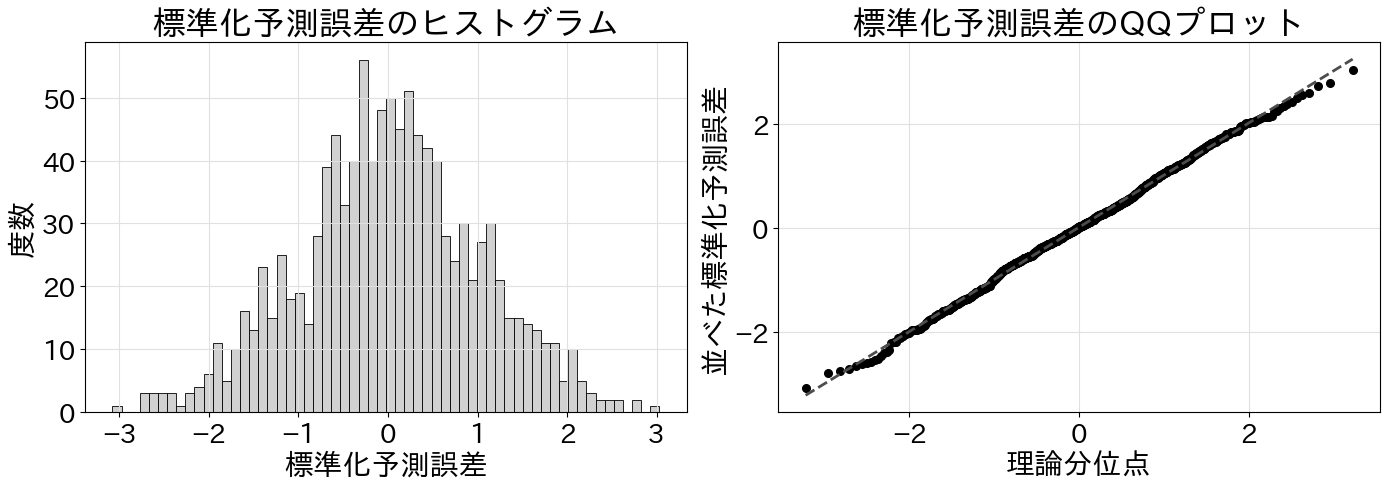

In [ ]:
# 標準化した1期先予測誤差の分布形を確認する
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats

diagnostic_start = max(
    result.loglikelihood_burn, result.filter_results.nobs_diffuse
)
standardized_error = result.filter_results.standardized_forecasts_error[
    0, diagnostic_start:
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 分布の全体像
axes[0].hist(
    standardized_error,
    bins=60,
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    linewidth=0.6,
)
axes[0].set_title("標準化予測誤差のヒストグラム", fontsize=24)
axes[0].set_xlabel("標準化予測誤差", fontsize=21)
axes[0].set_ylabel("度数", fontsize=21)
axes[0].tick_params(axis="both", labelsize=19)

# 正規分布からのずれを視覚的に確認
scipy_stats.probplot(standardized_error, dist="norm", plot=axes[1])
qq_points, qq_line = axes[1].get_lines()[:2]
qq_points.set_color(MONO_BLACK)
qq_points.set_marker("o")
qq_points.set_markersize(5.5)
qq_line.set_color(MONO_DARK)
qq_line.set_linestyle("--")
qq_line.set_linewidth(2.0)
axes[1].set_title("標準化予測誤差のQQプロット", fontsize=24)
axes[1].set_xlabel("理論分位点", fontsize=21)
axes[1].set_ylabel("並べた標準化予測誤差", fontsize=21)
axes[1].tick_params(axis="both", labelsize=19)

for ax in axes:
    ax.grid(color="0.88", linewidth=0.8)
fig.tight_layout()
plt.show()

### Ljung-Box検定による標準化予測誤差の確認

標準化予測誤差に時間に沿った規則性が残っていないかをLjung-Box検定で確認する。p値が小さい時点差では、モデルの設定や推定結果を見直す。


In [18]:
lb_values = result.test_serial_correlation(method="ljungbox", lags=20)[0]
lb_result = pd.DataFrame(
    {"lb_stat": lb_values[0], "lb_pvalue": lb_values[1]},
    index=np.arange(1, 21),
)
print("Ljung-Box検定: 標準化予測誤差の時間方向の関係を確認")
lb_display = lb_result[["lb_stat", "lb_pvalue"]].tail(5).copy()
lb_display["lb_stat"] = lb_display["lb_stat"].map(lambda x: f"{x:.3f}")
lb_display["lb_pvalue"] = lb_display["lb_pvalue"].map(lambda x: f"{x:.2e}")
lb_display

Ljung-Box検定: 標準化予測誤差の時間方向の関係を確認


,lb_stat,lb_pvalue
16,8.591,9.29e-01
17,8.699,9.49e-01
18,9.333,9.52e-01
19,9.589,9.62e-01
20,9.618,9.75e-01


## 第9章 第4節 第4項のコード

### 予測の実装：`get_forecast()`

第4節第4項「予測区間付きの長期予測」のコードです。

`get_forecast()`を使って、365日先までの予測値と80%予測区間を取得し、Polars DataFrameに整理する。

#### 処理内容

1. **365日先の予測**
   `result.get_forecast(steps=365)`で予測値と予測区間を取得する。

2. **予測区間の取り出し**
   `pred.conf_int(alpha=0.20)`で80%予測区間（alpha=1-coverage）を取得する。

3. **Polarsで整理**
   将来の日付（2025-01-01〜2025-12-31）と予測値・区間をDataFrameにまとめ、末尾を確認する。


In [19]:
# 365日先の予測（予測区間付き）
forecast_steps = 365
pred = result.get_forecast(steps=forecast_steps)

# 予測値と予測区間を取り出す
pred_mean = pred.predicted_mean  # 予測値
pred_ci = pred.conf_int(alpha=0.20)  # 80%予測区間（alpha=1-coverage）

# Polarsで整理
future_dates = pl.date_range(
    start=pl.date(2025, 1, 1),
    end=pl.date(2025, 12, 31),
    interval="1d",
    eager=True,
)

forecast_df = pl.DataFrame(
    {
        "date": future_dates,
        "yhat": pred_mean.values,
        "yhat_lower": pred_ci.iloc[:, 0].values,
        "yhat_upper": pred_ci.iloc[:, 1].values,
    }
)
forecast_df.tail()

date,yhat,yhat_lower,yhat_upper
date,f64,f64,f64
2025-12-27,2.2524e6,2.1111e6,2.3936e6
2025-12-28,2.2571e6,2.1155e6,2.3987e6
2025-12-29,2.2573e6,2.1154e6,2.3992e6
2025-12-30,2.2173e6,2.0751e6,2.3595e6
2025-12-31,2.2323e6,2.0896e6,2.3750e6


### 予測のグラフ：学習に使った期間と将来を一枚に

学習に使った期間の実績と将来予測を同じグラフに描き、予測の開始点と予測区間を確認する。


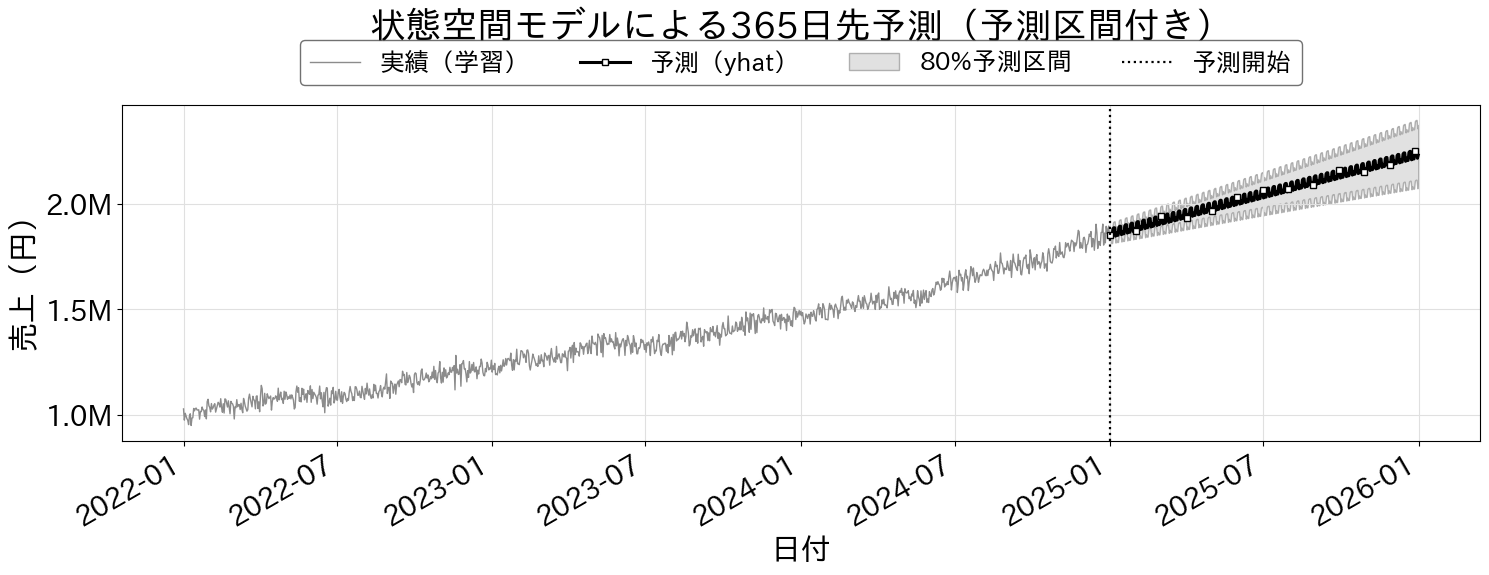

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 6))

# 学習データ
ax.plot(
    pd.to_datetime(df["date"].to_numpy()),
    df["sales"].to_numpy(),
    color=MONO_MID,
    lw=1.0,
    label="実績（学習）",
)

# 将来予測
future_idx = pd.to_datetime(forecast_df["date"].to_numpy())
ax.plot(
    future_idx,
    forecast_df["yhat"].to_numpy(),
    color=MONO_BLACK,
    lw=2.2,
    marker="s",
    markevery=30,
    markersize=5,
    markerfacecolor="white",
    label="予測（yhat）",
)
ax.fill_between(
    future_idx,
    forecast_df["yhat_lower"].to_numpy(),
    forecast_df["yhat_upper"].to_numpy(),
    facecolor=MONO_LIGHT,
    edgecolor=MONO_MID,
    alpha=0.65,
    label="80%予測区間",
)

# 境界線
ax.axvline(
    pd.Timestamp("2025-01-01"),
    color=MONO_BLACK,
    lw=1.6,
    ls=":",
    label="予測開始",
)

ax.set_title(
    "状態空間モデルによる365日先予測（予測区間付き）",
    fontsize=26,
    y=1.20,
    pad=0,
)
ax.set_xlabel("日付", fontsize=22)
ax.set_ylabel("売上（円）", fontsize=22)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=4,
    fontsize=18,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)
ax.tick_params(axis="both", labelsize=20)
ax.grid(color="0.88", linewidth=0.8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### 予測区間の広がりを数値で示す

1か月後・3か月後・6か月後・12か月後の予測区間の幅を比較し、時間とともに不確実性が広がる様子を確認する。


In [ ]:
# 予測区間の幅の時間による変化を確認
forecast_df_with_width = forecast_df.with_columns(
    (pl.col("yhat_upper") - pl.col("yhat_lower")).alias("ci_width")
)

# 1か月後・3か月後・6か月後・12か月後の区間の幅
checkpoints = [30, 90, 180, 365]
print("予測区間の幅の推移（80%区間）:")
for h in checkpoints:
    row = forecast_df_with_width[h - 1]
    width = row["ci_width"][0]
    yhat = row["yhat"][0]
    print(
        f"  {h:3d}日後: ±{width / 2:>10,.0f}円  "
        f"（予測値比 ±{width / 2 / yhat * 100:.1f}%）"
    )

予測区間の幅の推移（80%区間）:
   30日後: ±    37,806円  （予測値比 ±2.0%）
   90日後: ±    55,370円  （予測値比 ±2.8%）
  180日後: ±    82,202円  （予測値比 ±4.0%）
  365日後: ±   142,687円  （予測値比 ±6.4%）
